# 11. 1D Grating Mode Profiles and Vertical Field Cross-Sections

## Physical Motivation & Learning Objectives
Visualizing the spatial structure of electromagnetic fields provides vital physical insight into modal confinement and evanescent decay. In this tutorial:
1. We compute 1D Bloch modes in a lamellar grating with `plotting_fields=True`.
2. We visualize individual Bloch mode profiles (`plotting.Bloch_fields_1d`).
3. We compute fast 2D vertical $(x, z)$ cross-sections using `plotting.fields_interpolator_cross_section`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Grating Setup & Near-Field Solution


In [2]:
wl = 615.0      # nm
period = 600.0  # nm

light = objects.Light(wl, max_order_PWs=2, theta=0.0, phi=0.0)

superstrate = objects.ThinFilm(period, height_nm='semi_inf', world_1d=True, material=materials.Air, loss=False)
spacer      = objects.ThinFilm(period, height_nm=200.0, world_1d=True, material=materials.SiO2, loss=True)
grating     = objects.NanoStruct(
    '1D_array', period, int(round(0.7 * period)), height_nm=400.0,
    background=materials.Material(1.45),
    inclusion_a=materials.Material(3.77 + 0.01j),
    loss=True, lc_bkg=0.01, plotting_fields=True, plt_msh=False
)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', world_1d=True, material=materials.Air, loss=False)

sim_sup = superstrate.calc_modes(light)
sim_grt = grating.calc_modes(light, num_BMs=20)
sim_spc = spacer.calc_modes(light)
sim_sub = substrate.calc_modes(light)

stk = Stack((sim_sub, sim_spc, sim_grt, sim_sup))
stk.calc_scat(pol='TE')


## Visualizing Individual 1D Bloch Modes


<ipython-input-1-788c9c3c1c2f>:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


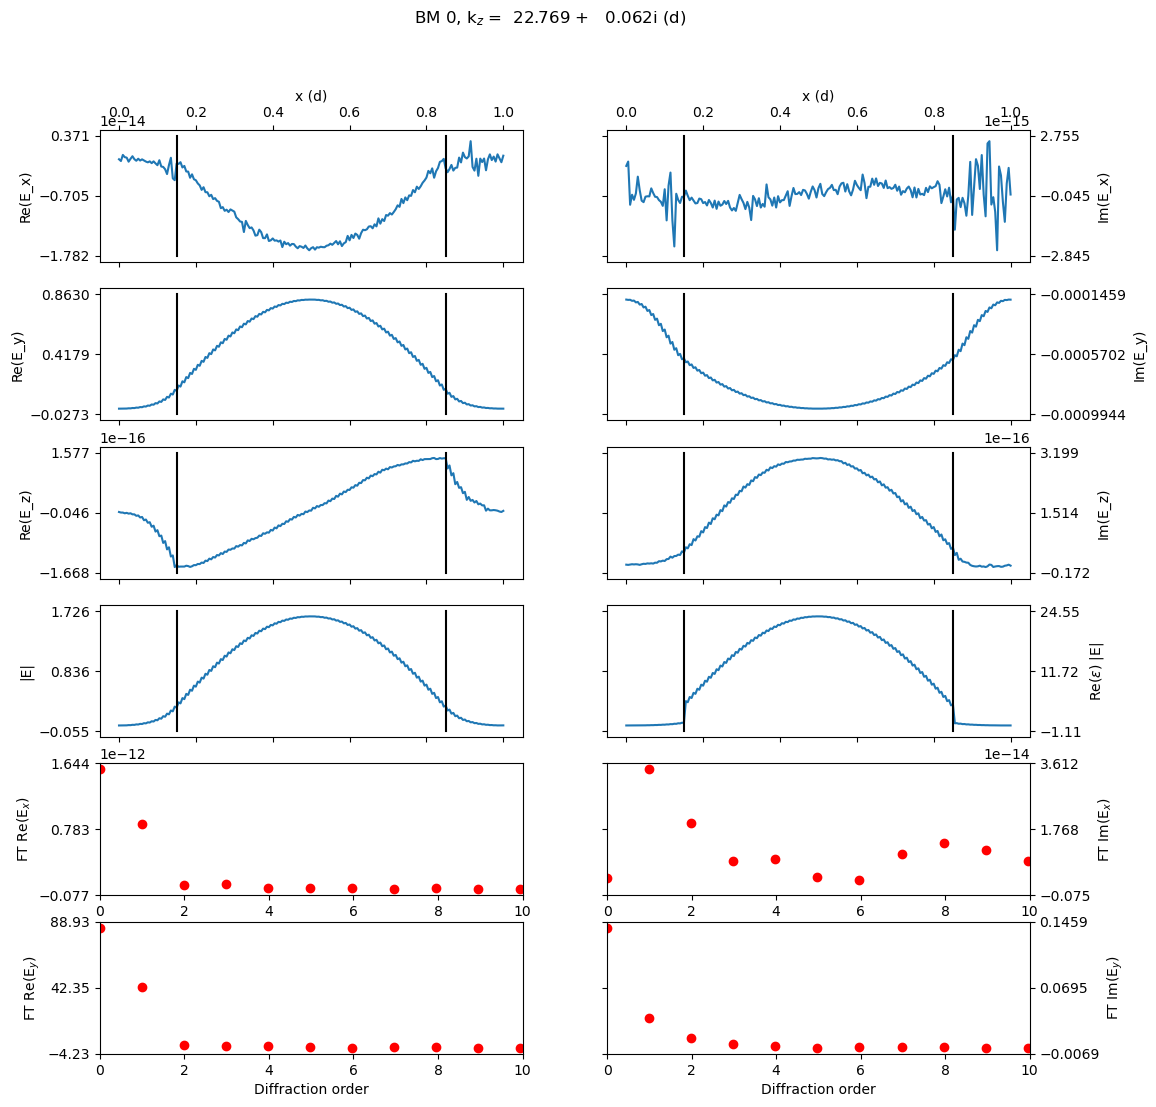

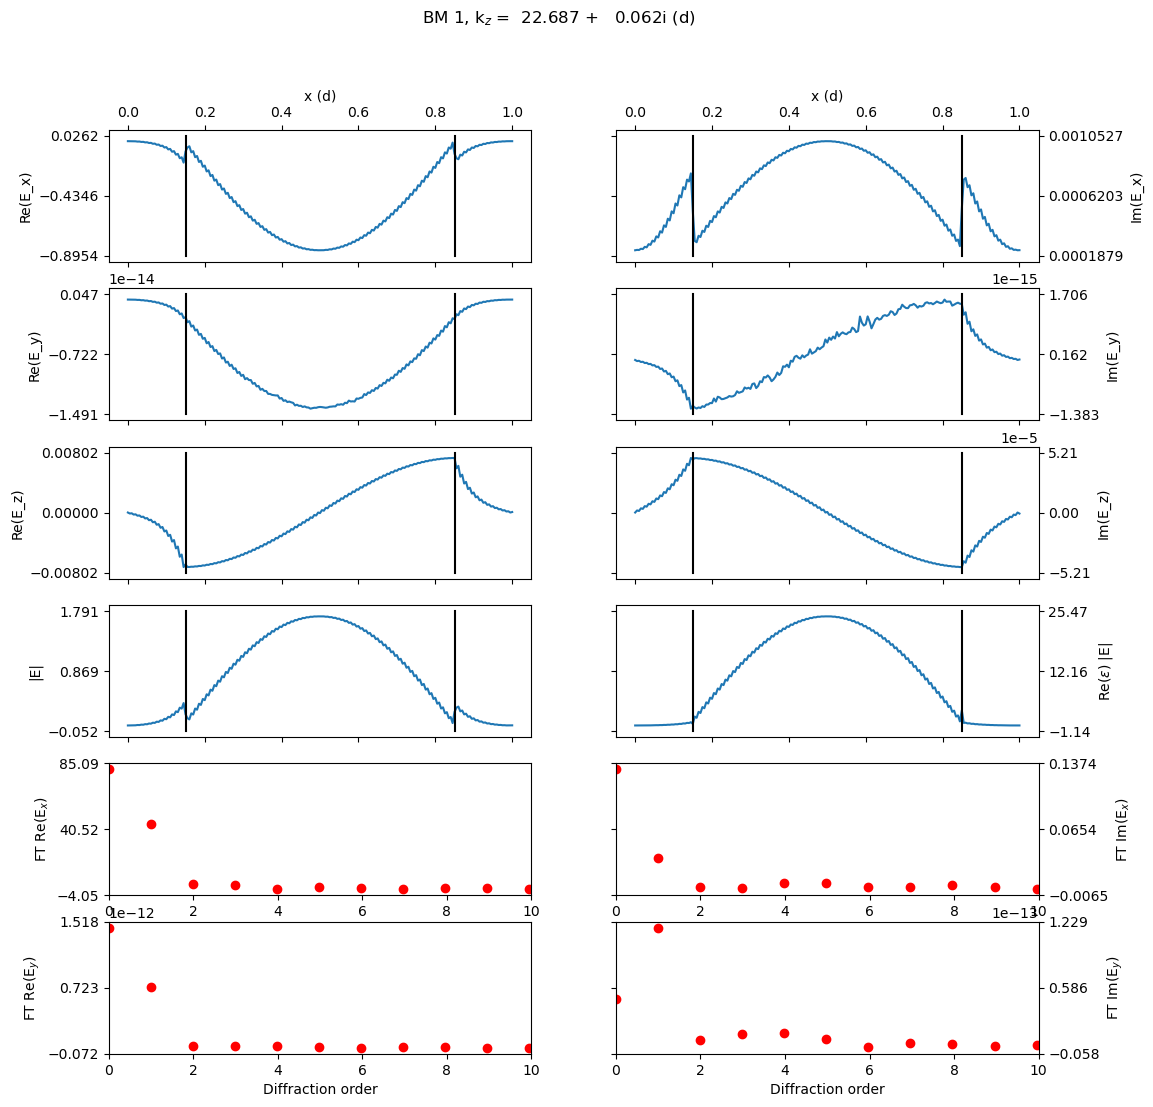

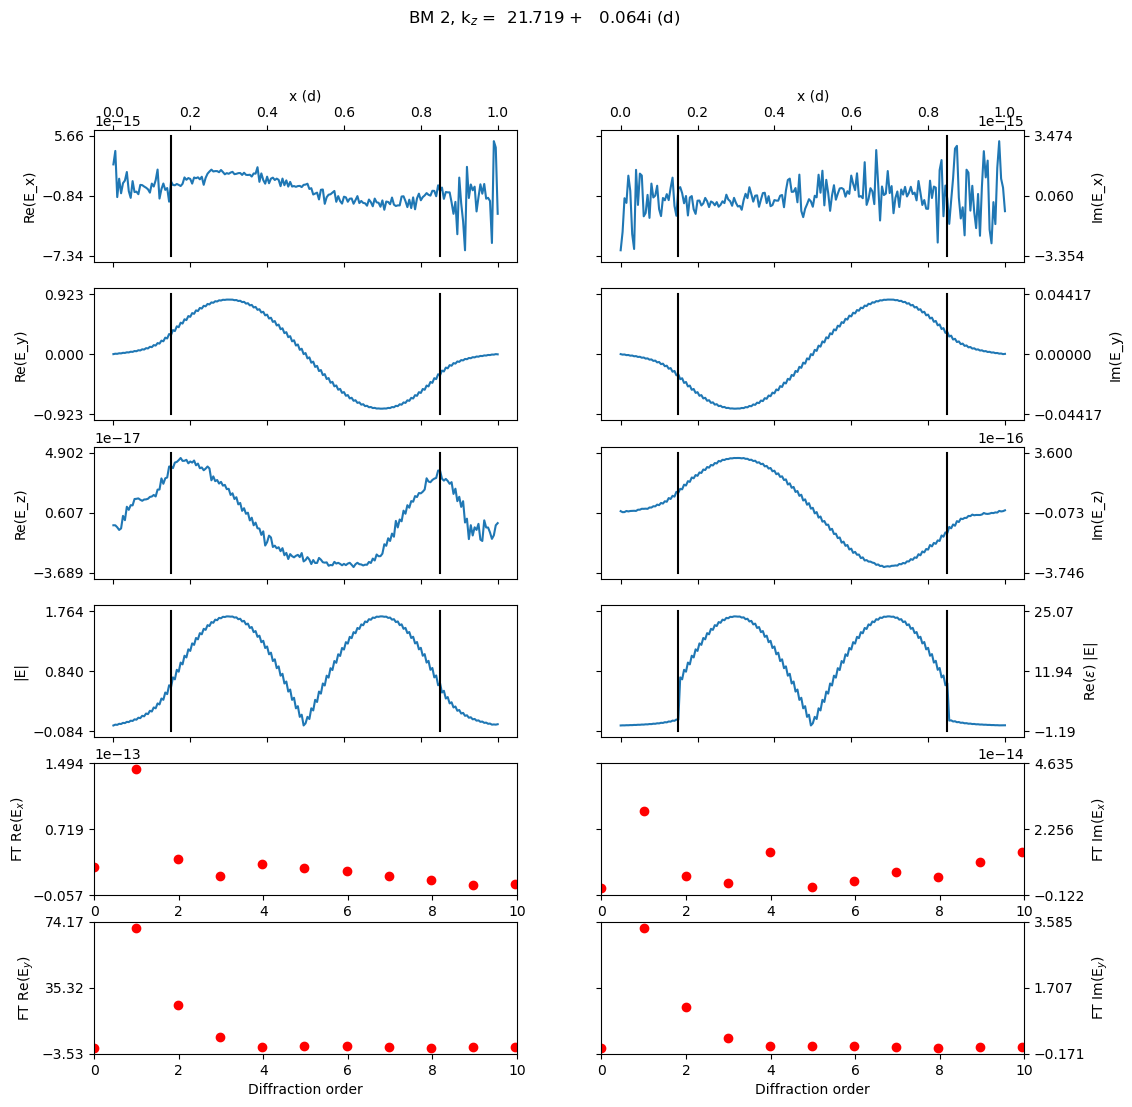

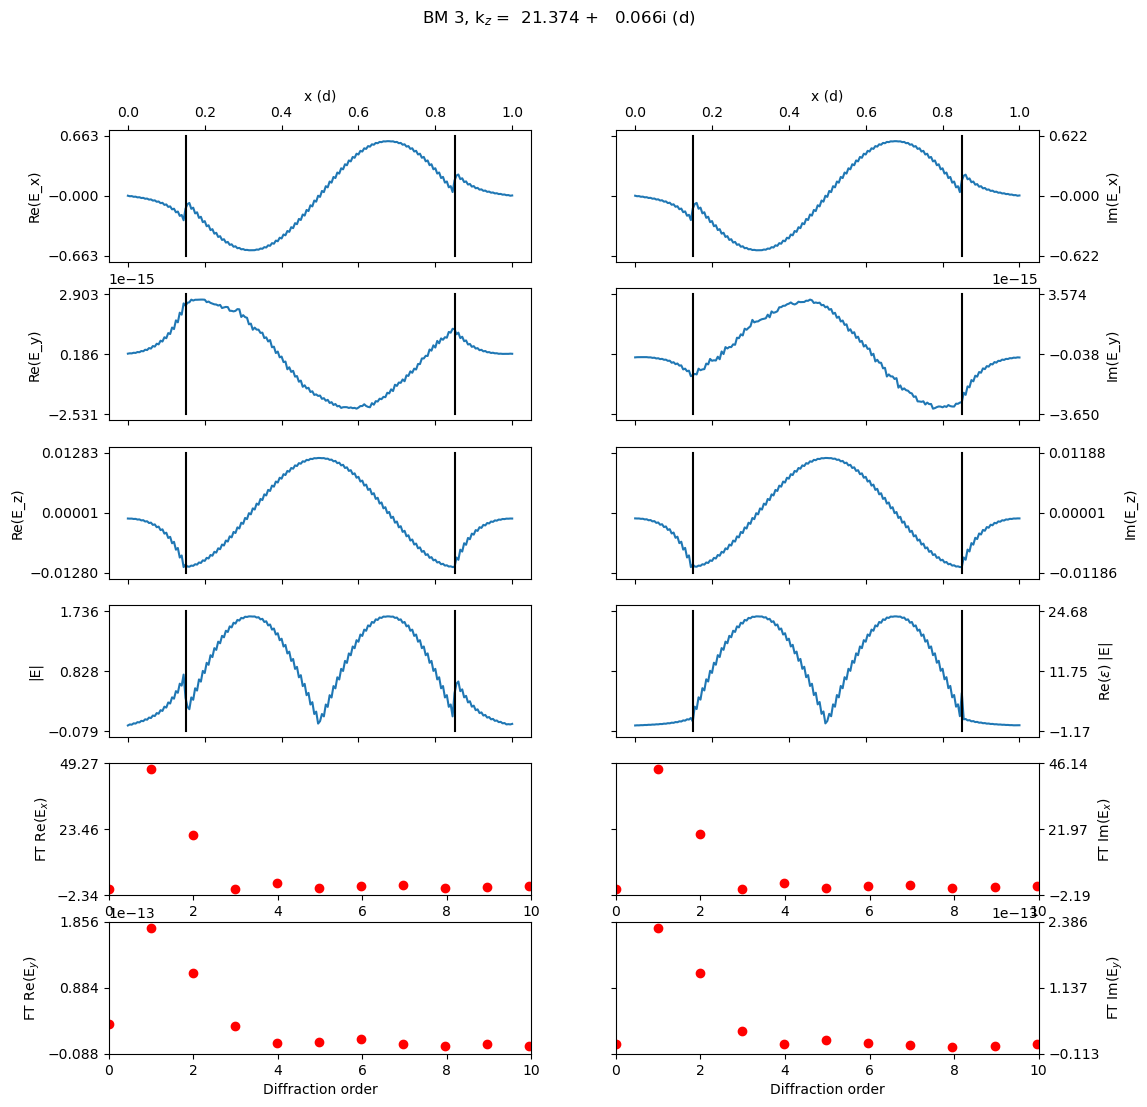

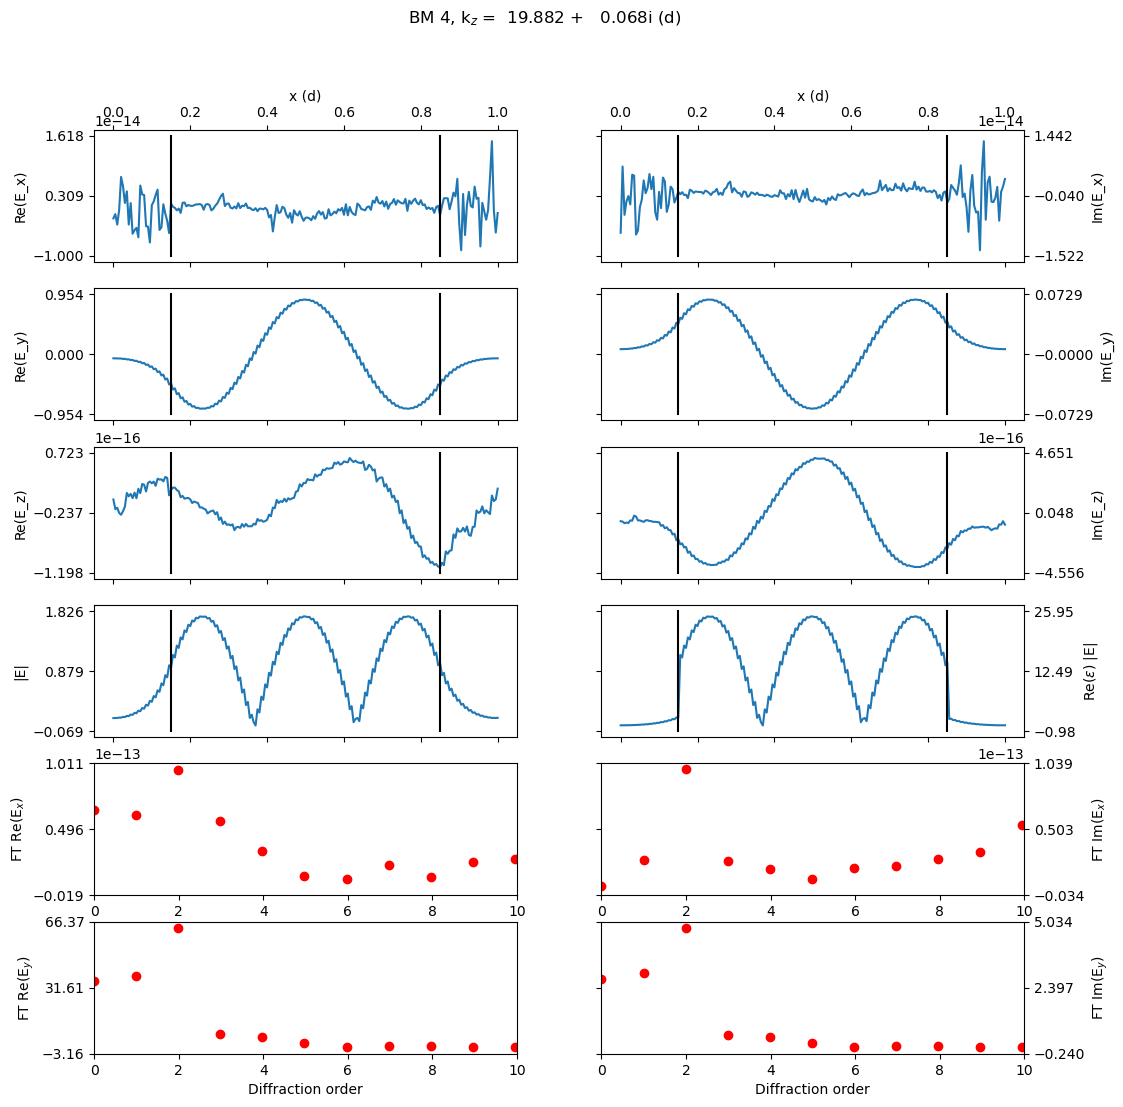

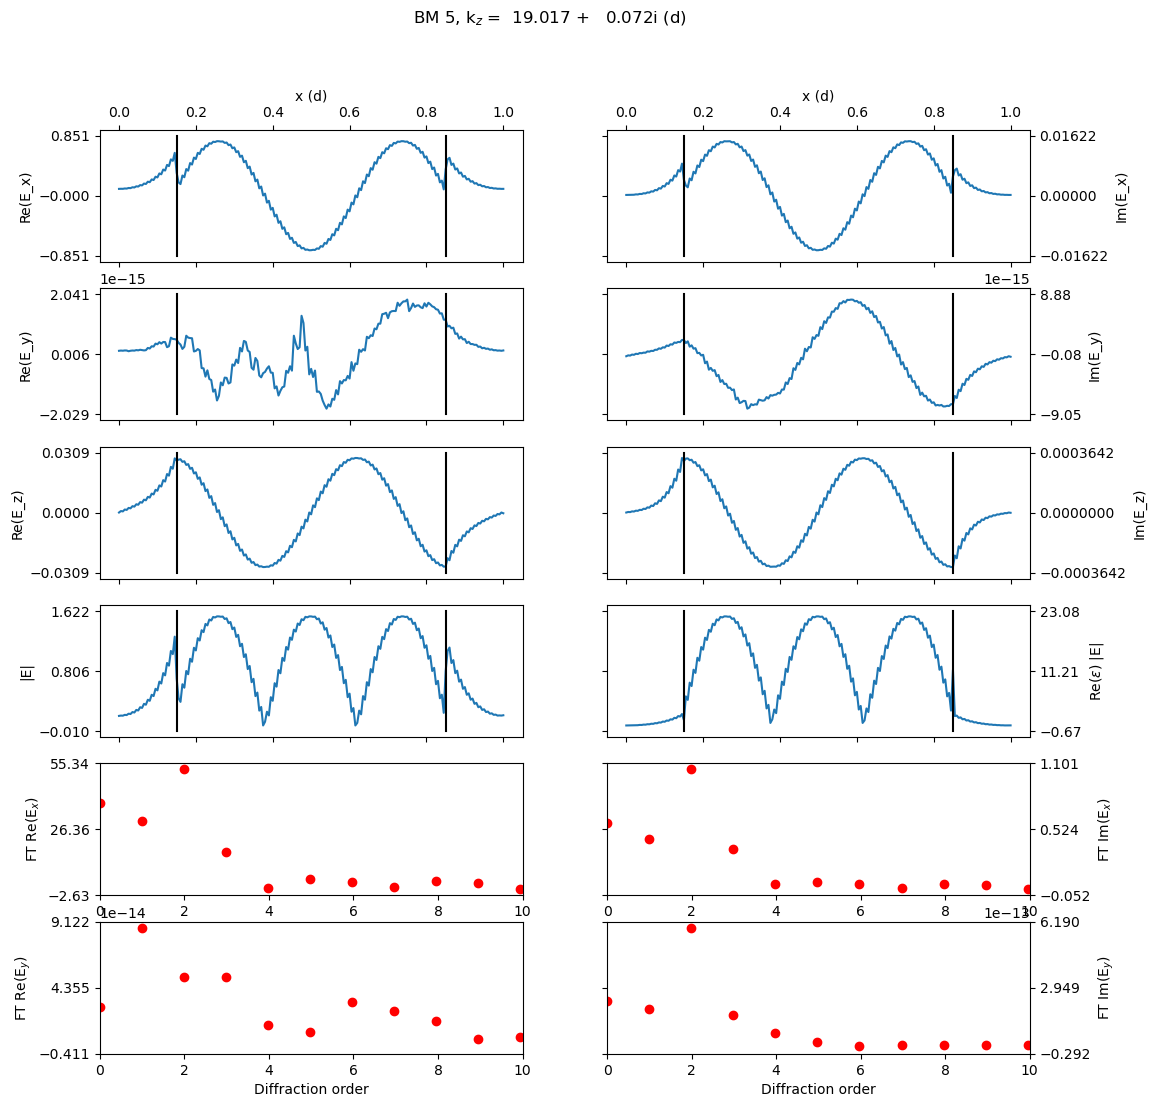

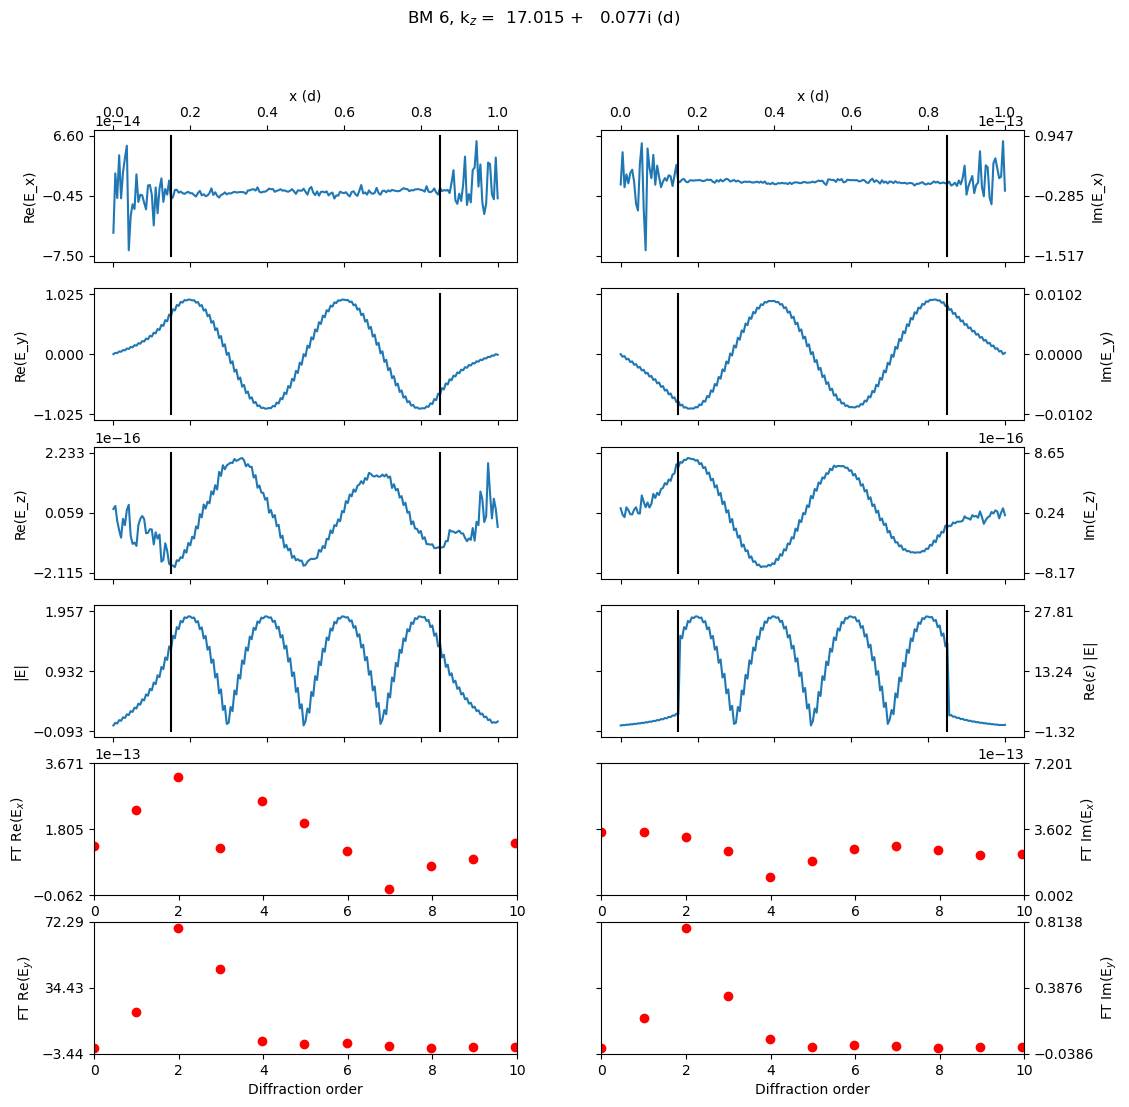

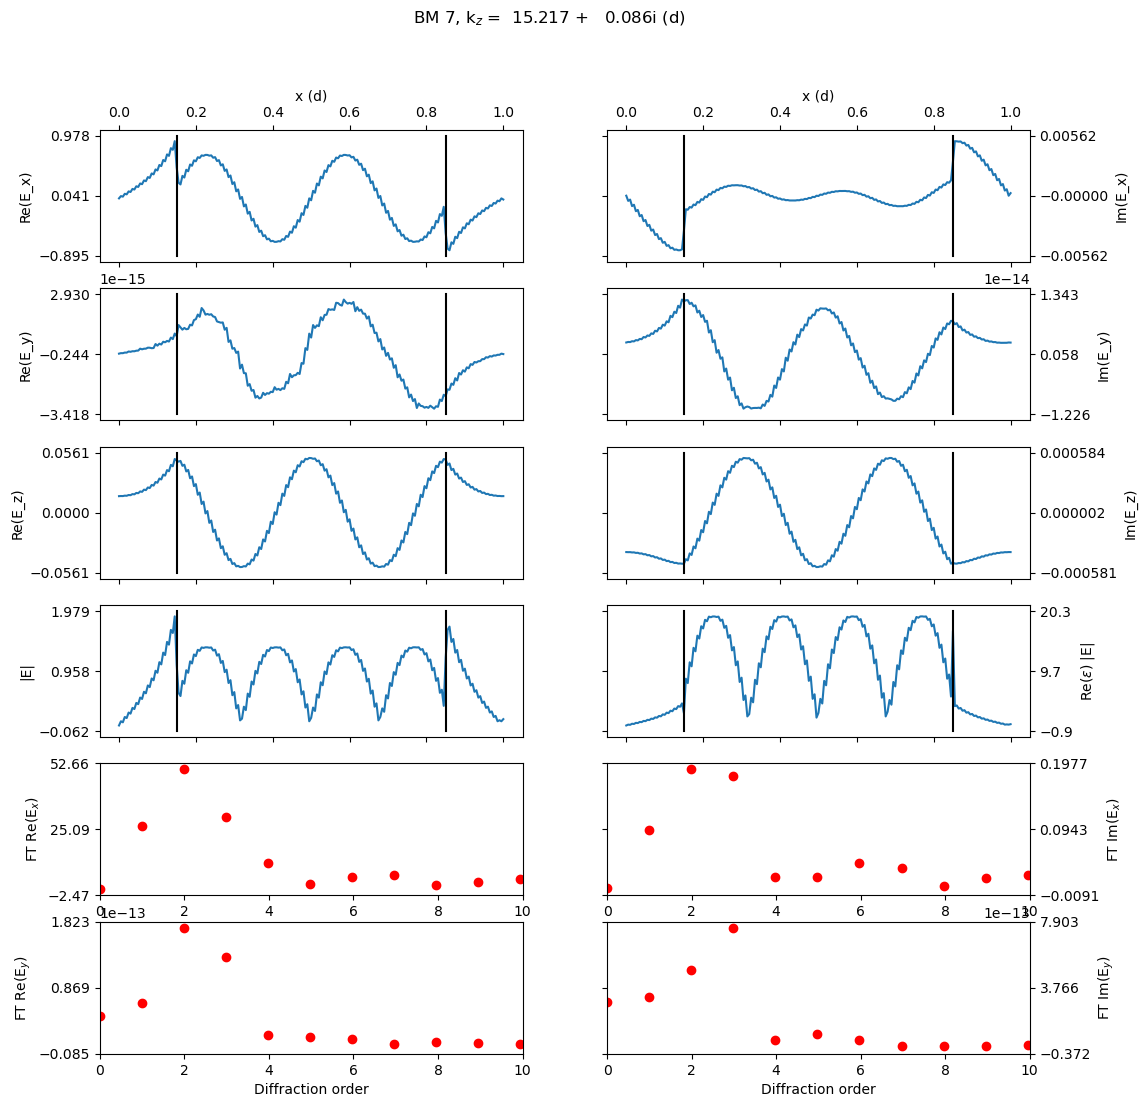

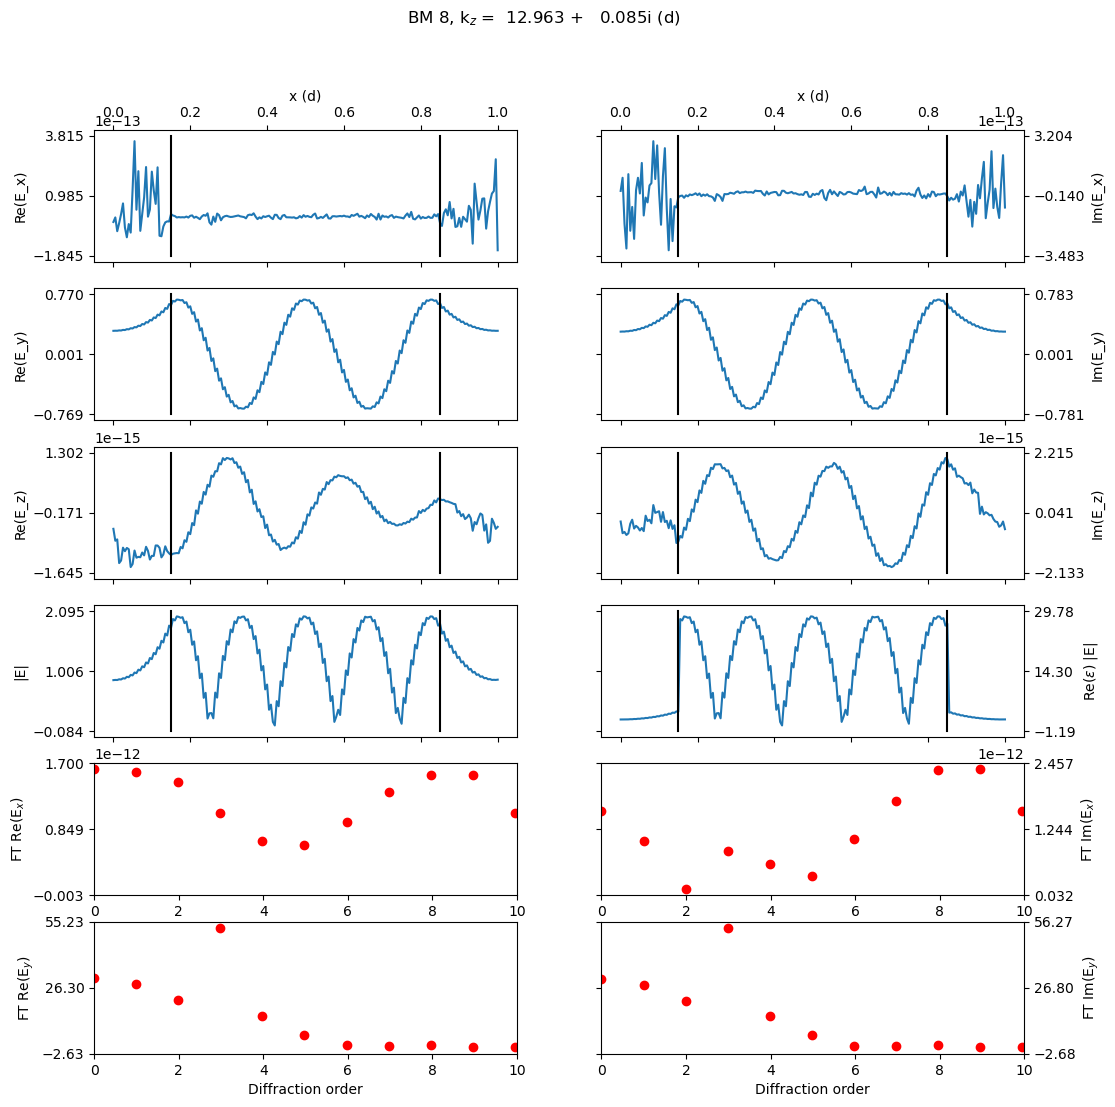

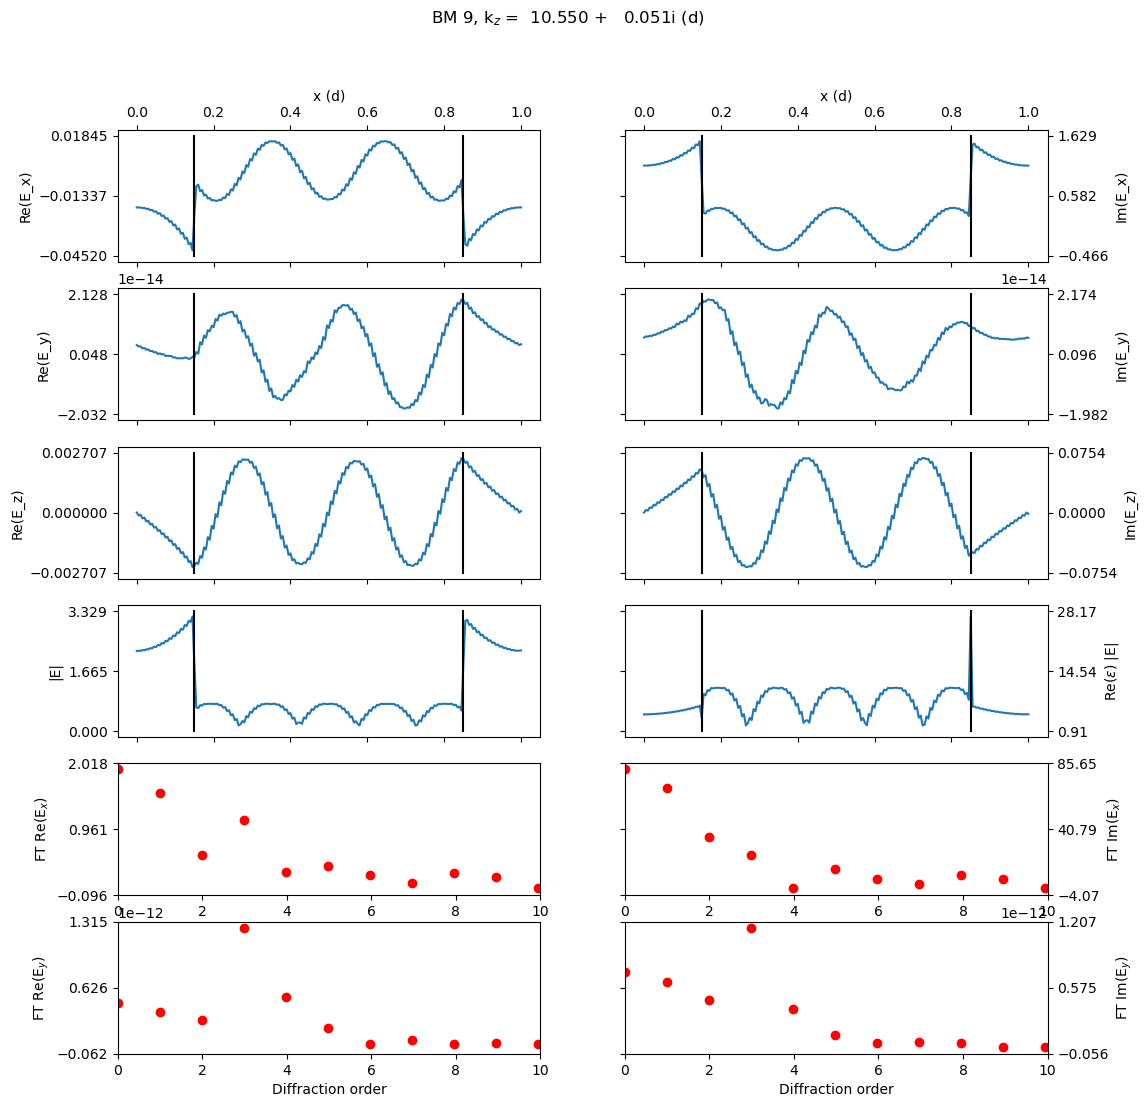

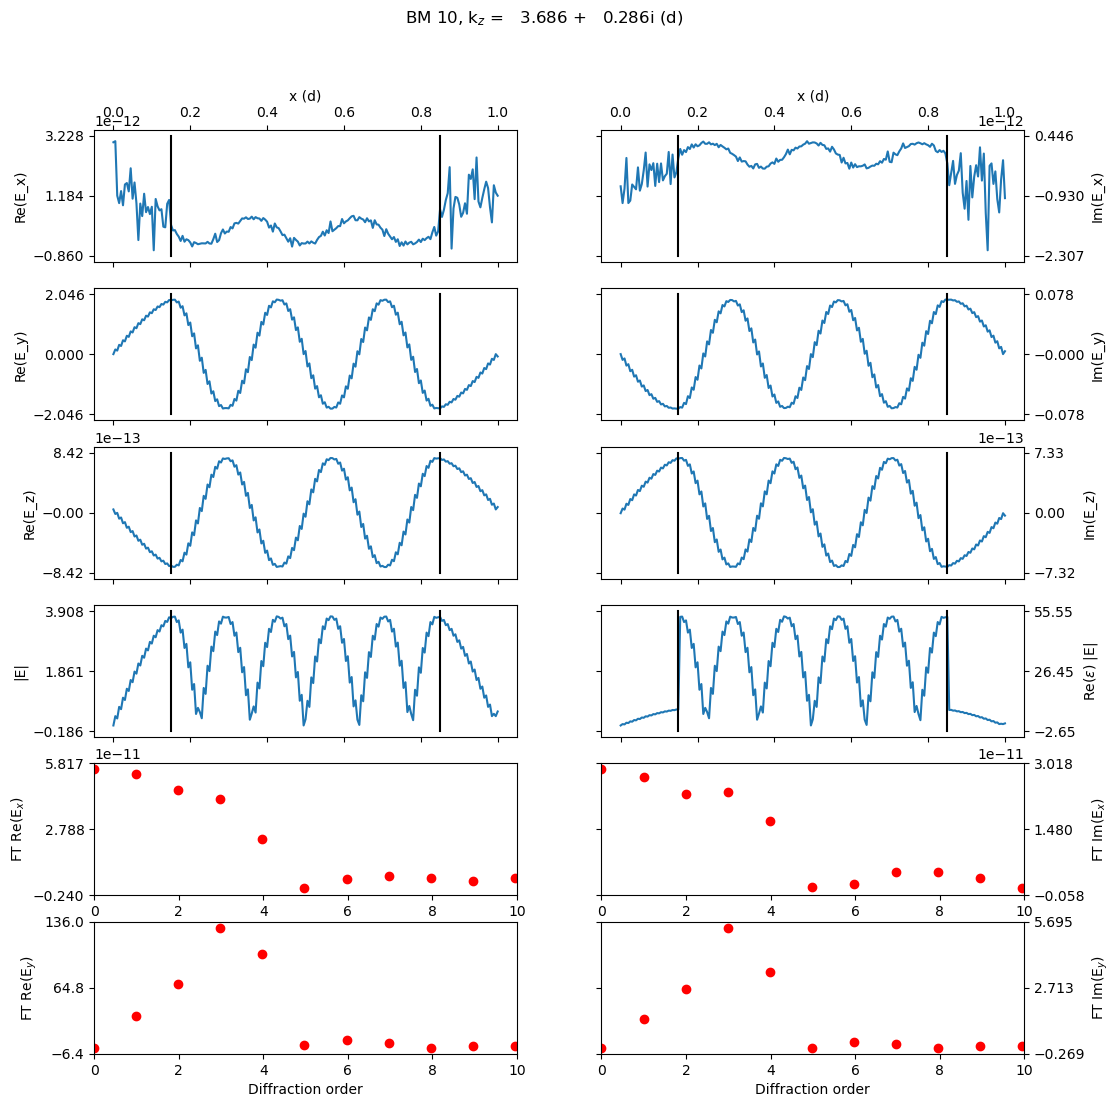

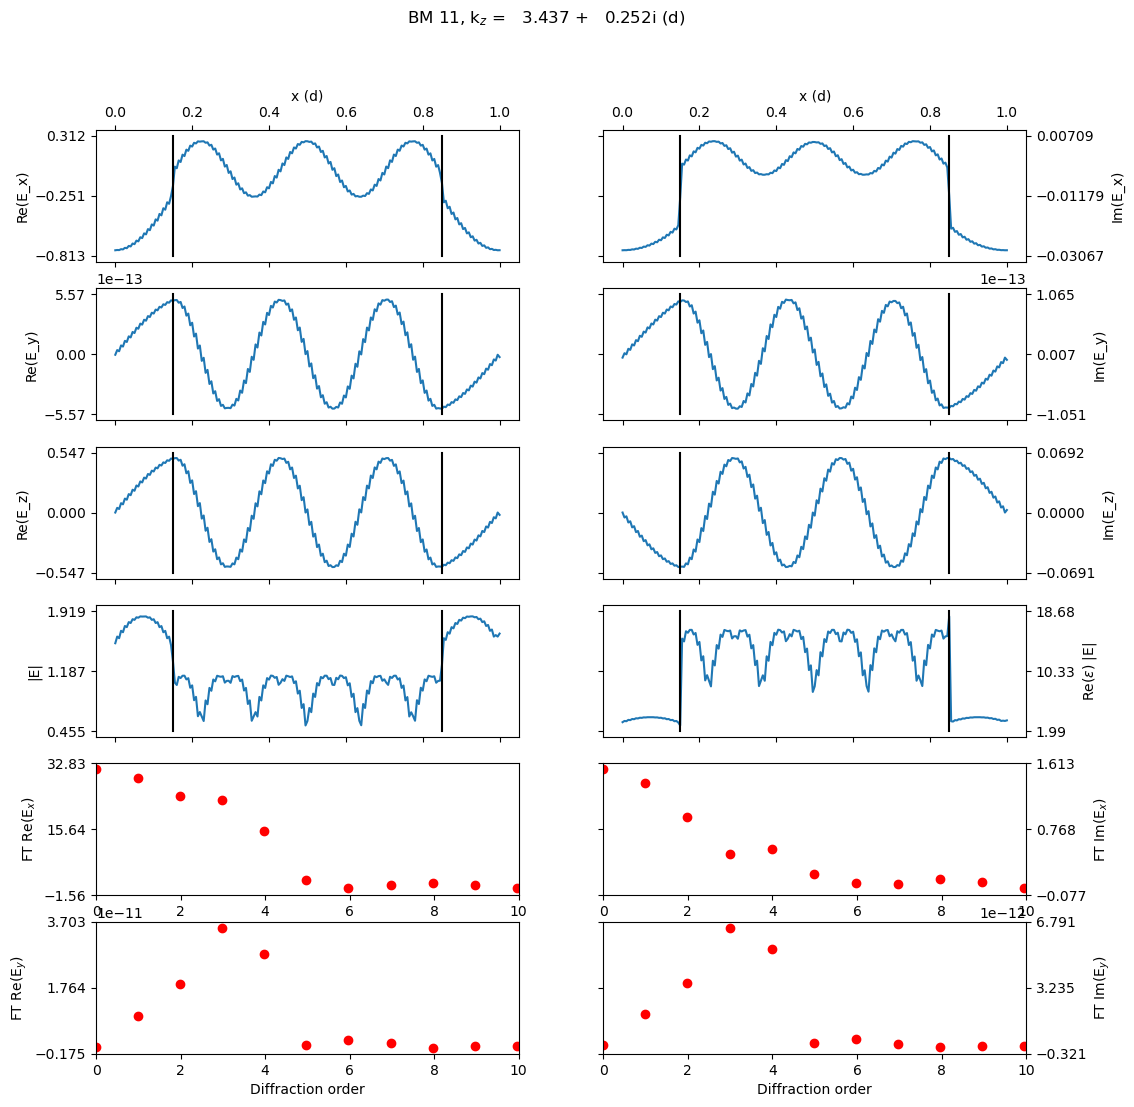

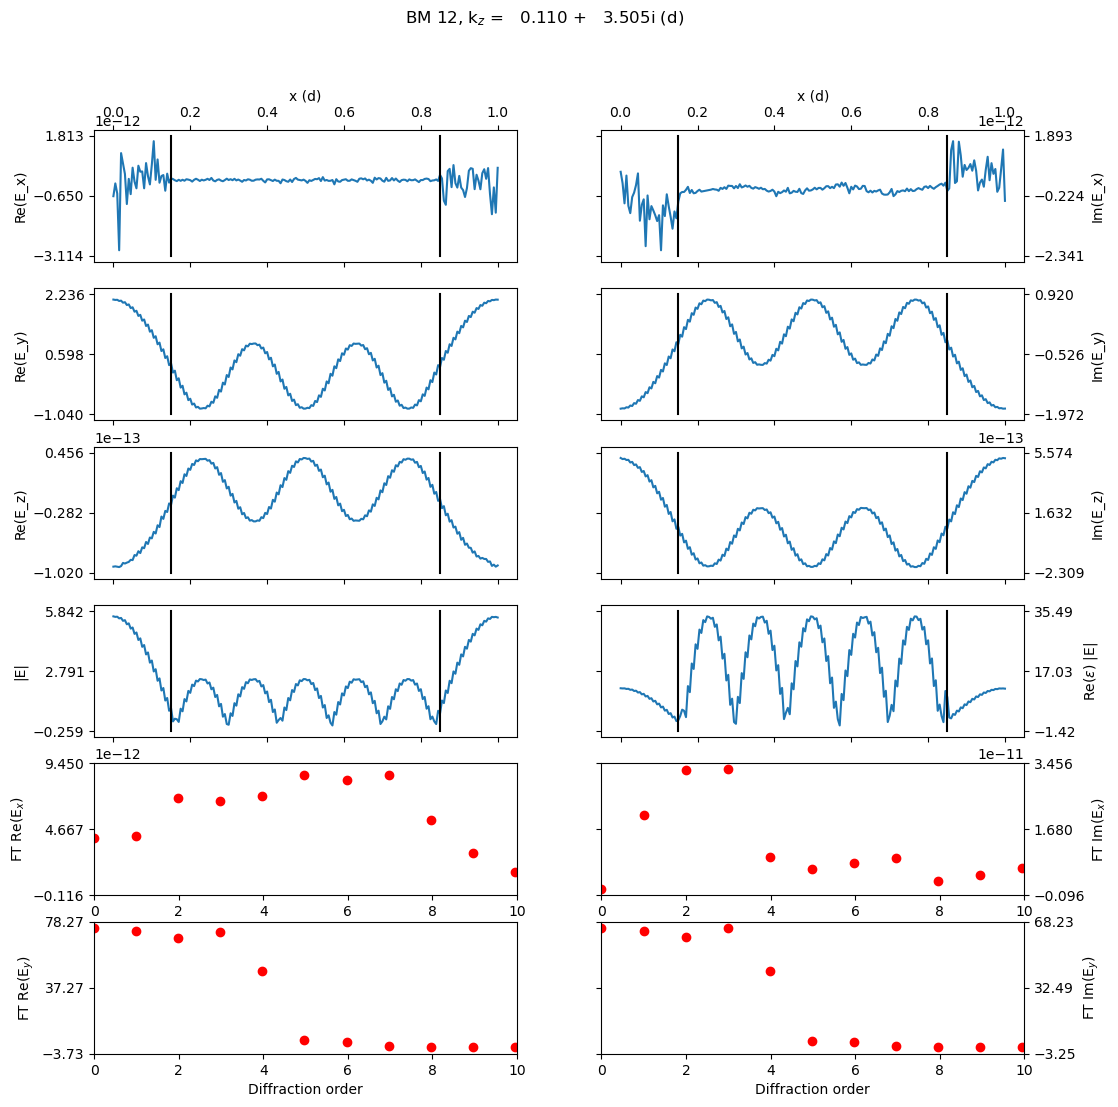

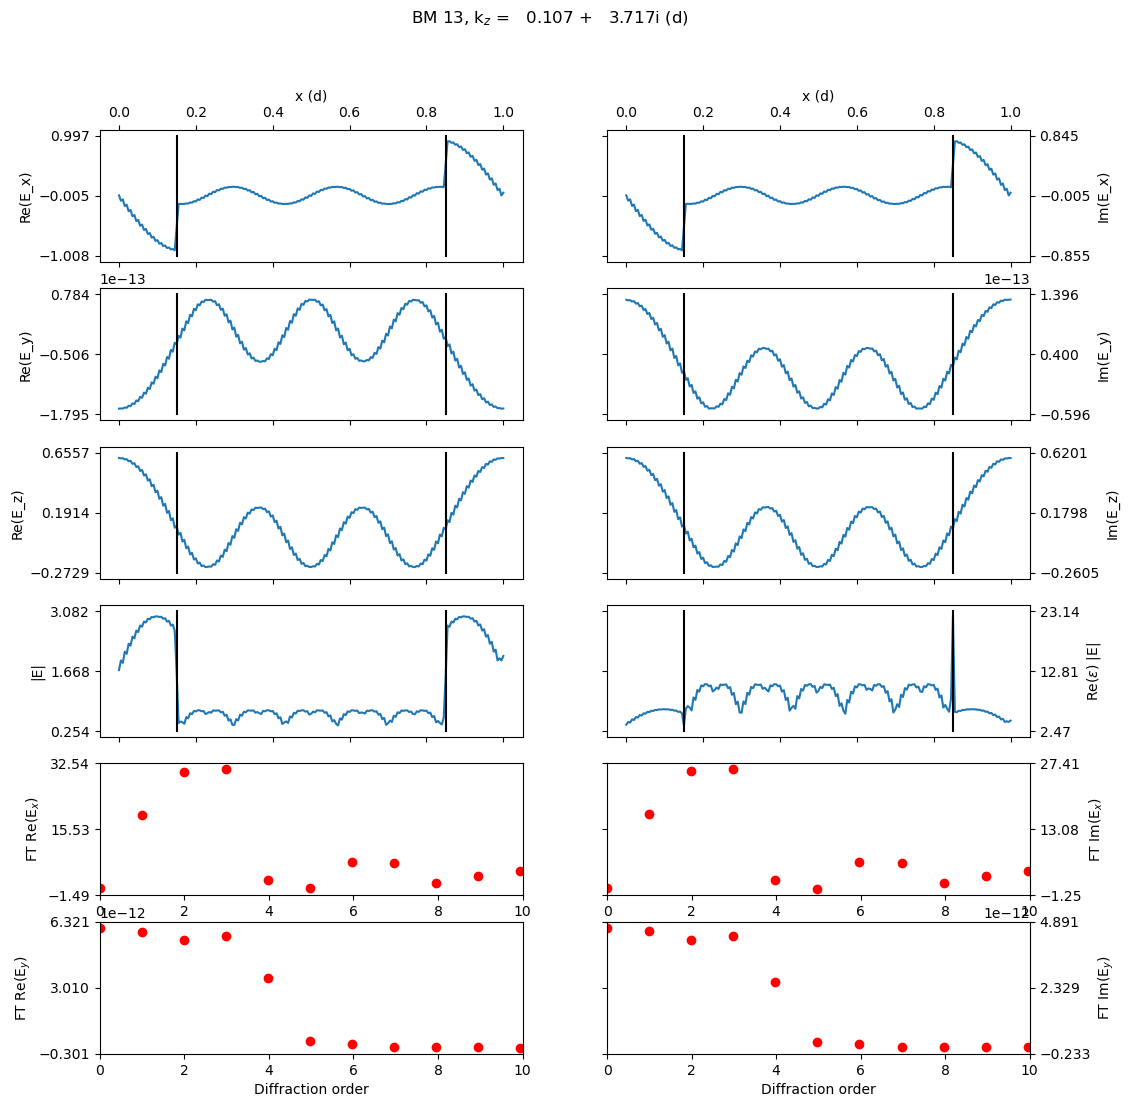

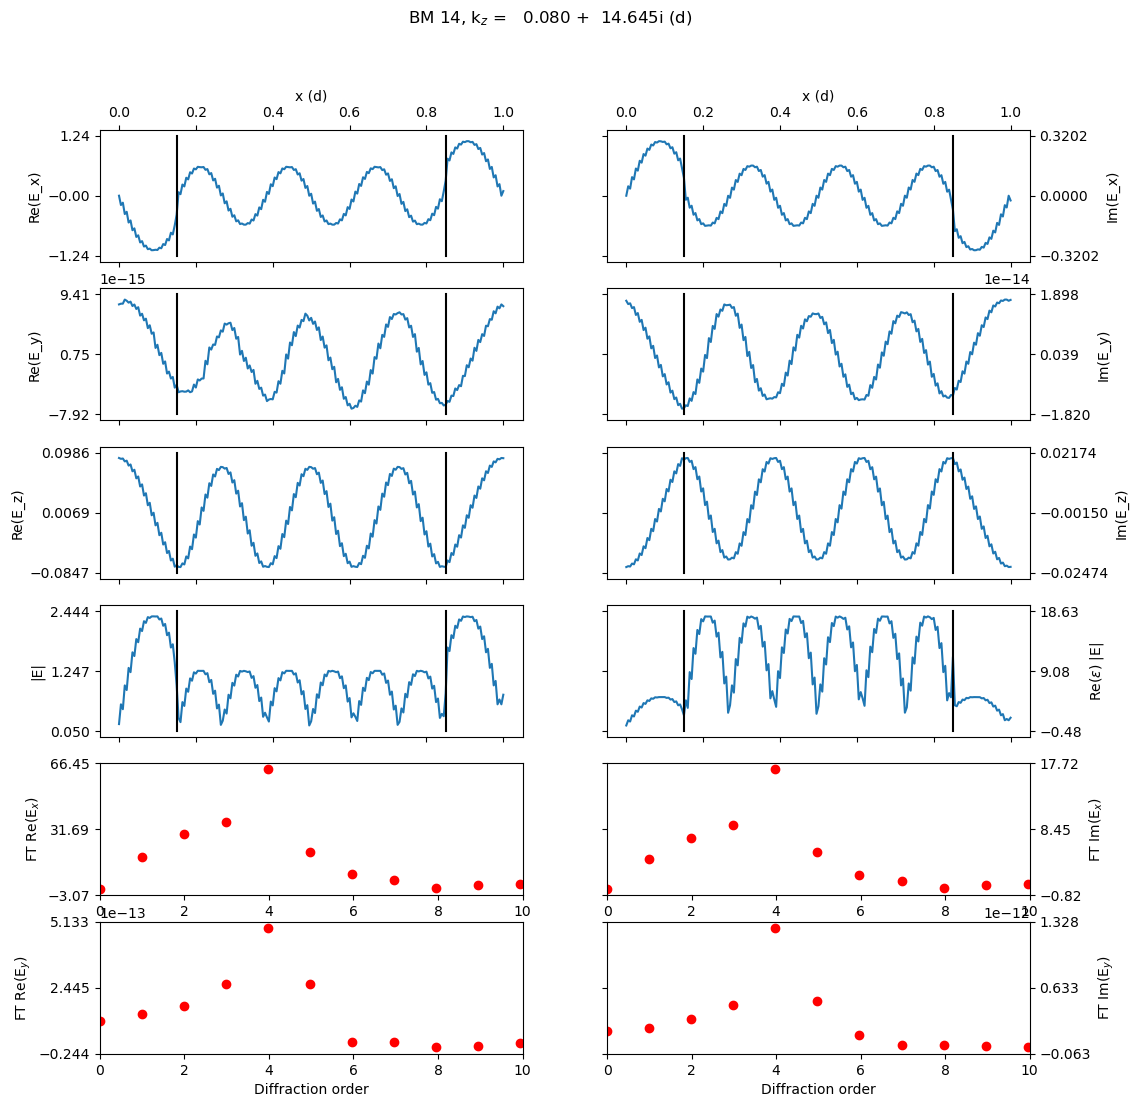

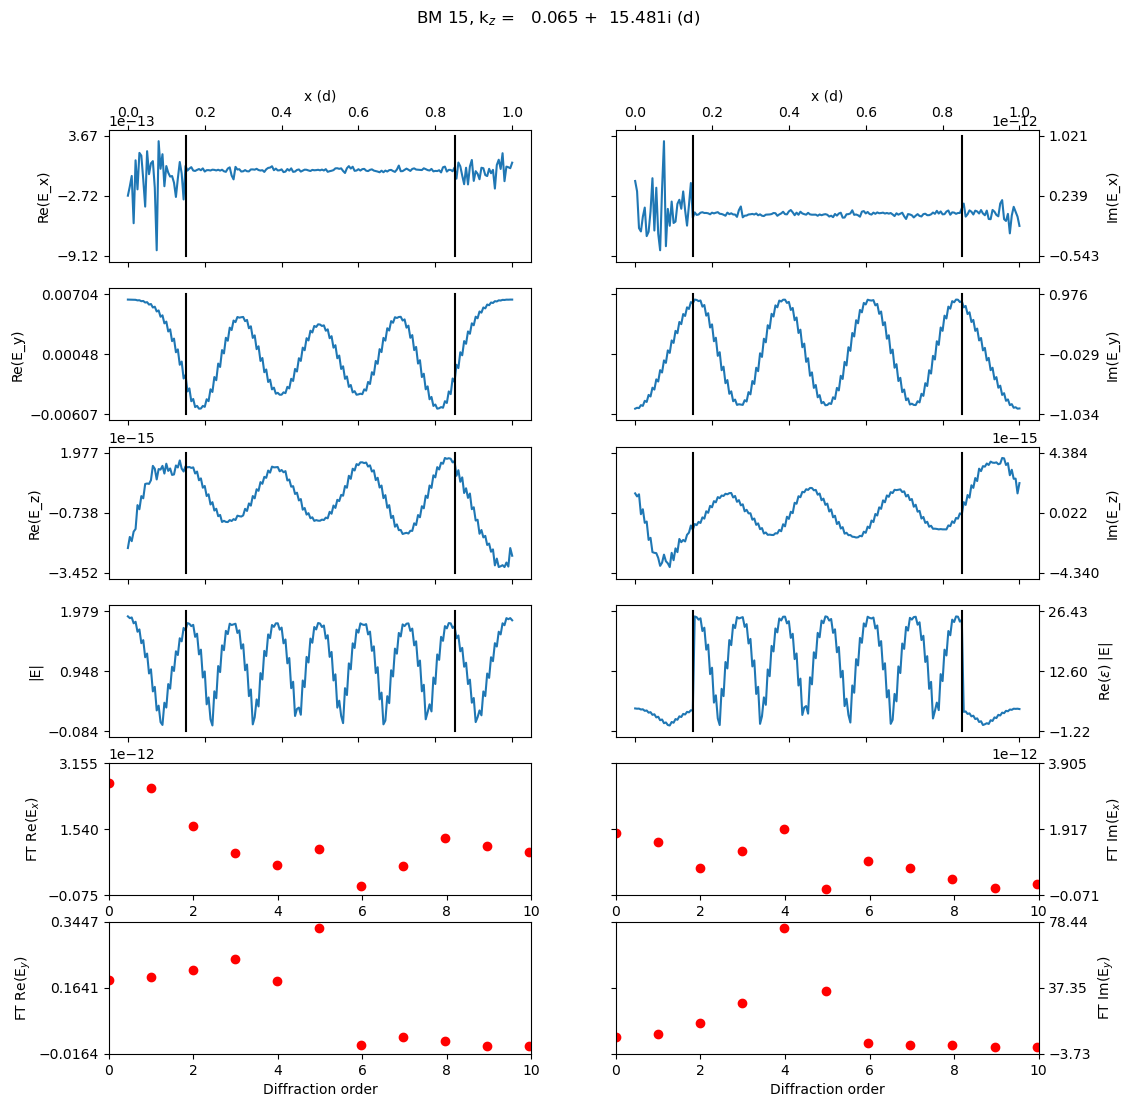

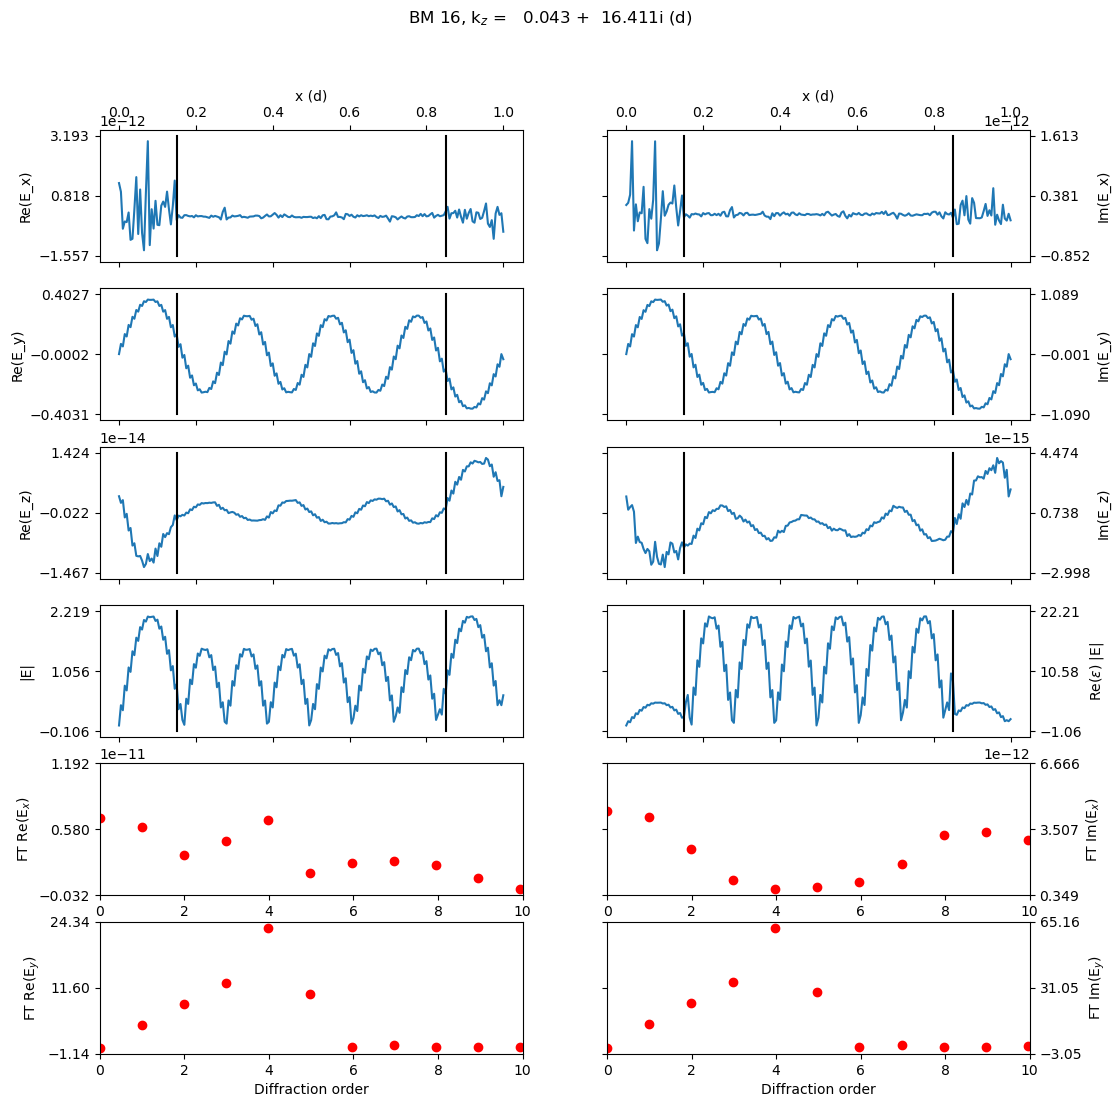

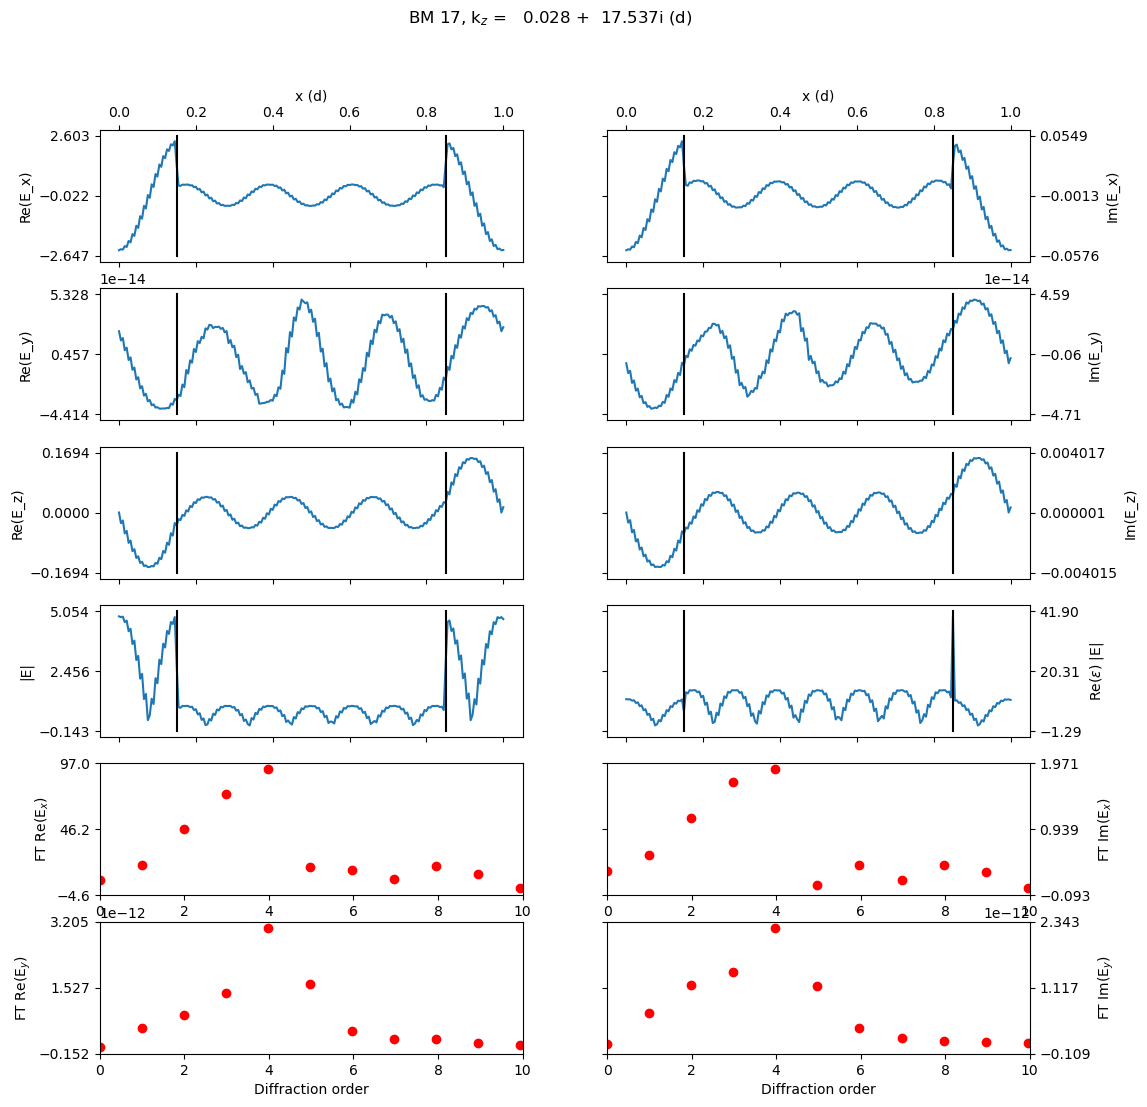

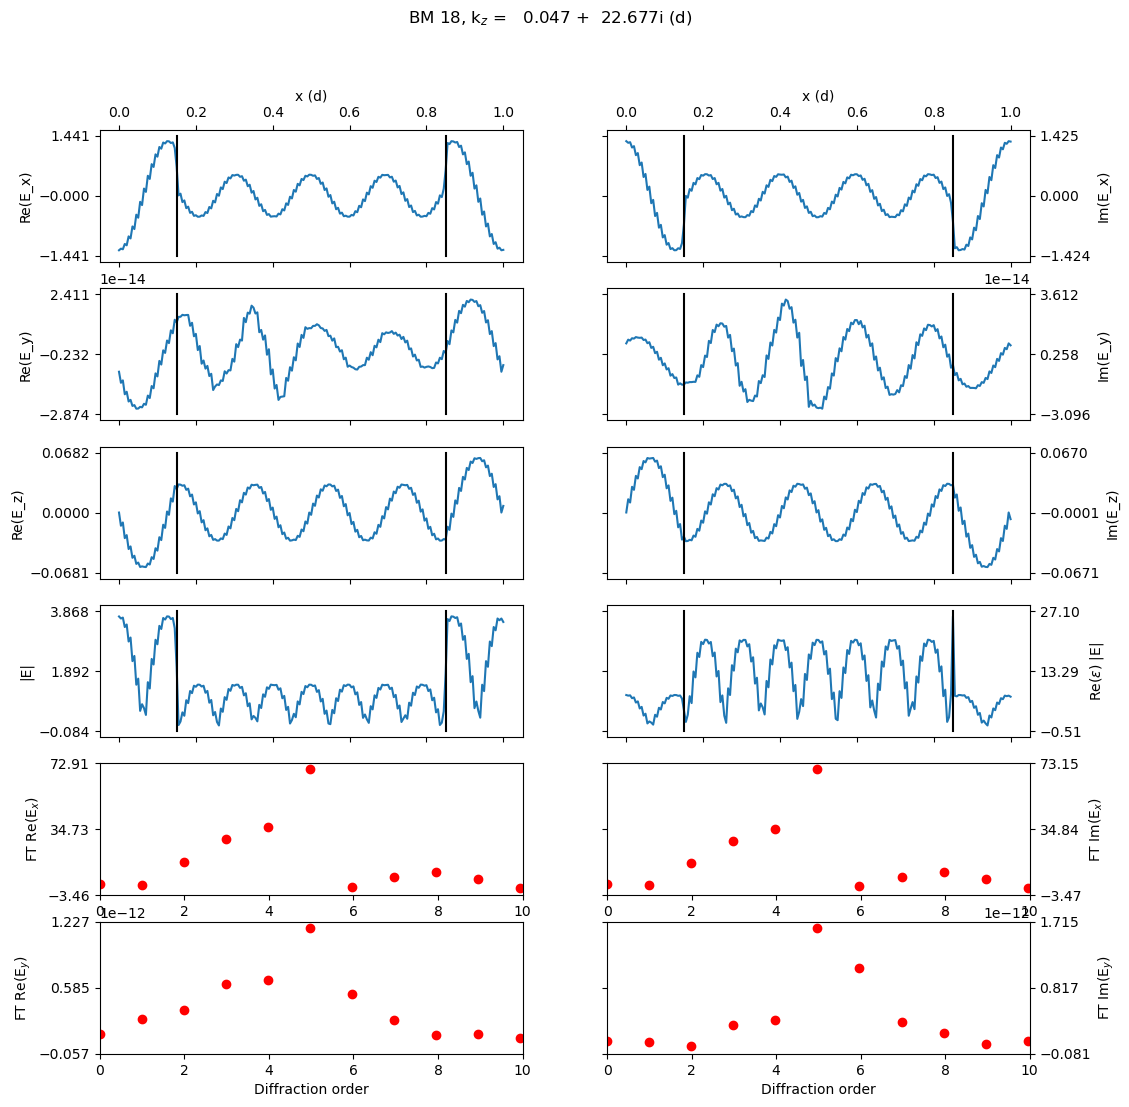

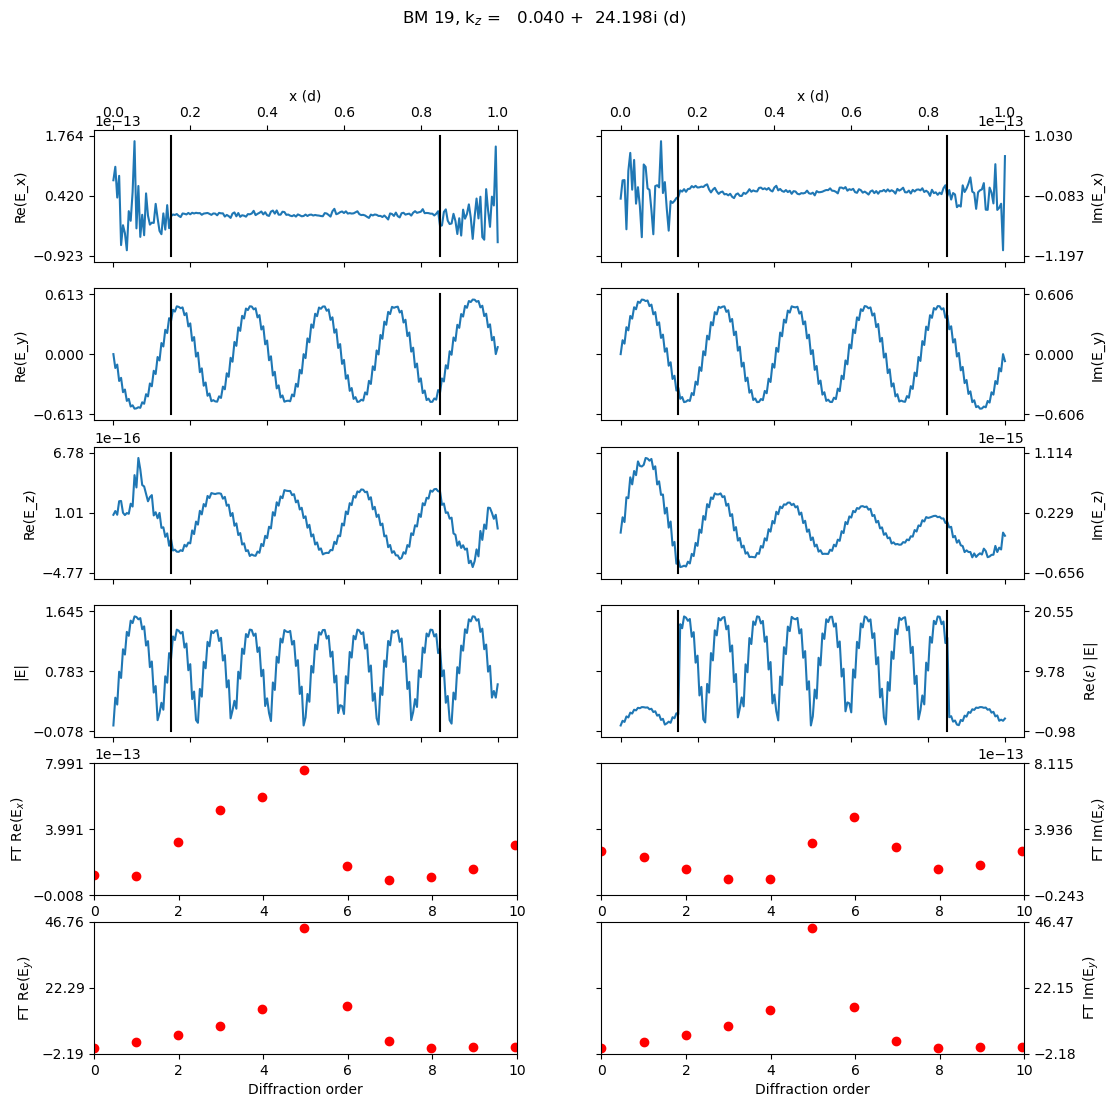

In [3]:
figs_bm = plotting.Bloch_fields_1d([stk], save_pdf=False)
plt.show()


## 2D Vertical $(x, z)$ Cross-Section Map Across Full Stack


<ipython-input-1-f8e08f351c0e>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


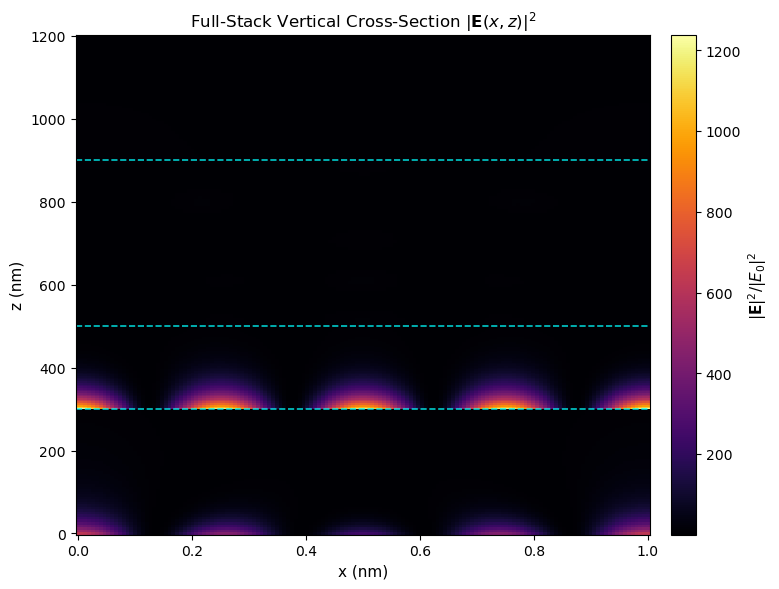

In [4]:
bundle_xz = plotting.fields_interpolator_cross_section(
    stk, plane='xz', slice_coord=0.5, n_horiz=150, n_vert_per_layer=50, return_H=True
)

X, Z = np.meshgrid(bundle_xz.u_grid, bundle_xz.v_grid, indexing='ij')
E_norm2 = bundle_xz.AbsE(X, Z)**2

fig, ax = plt.subplots(figsize=(8, 6), dpi=110)
im = ax.pcolormesh(X, Z, E_norm2, shading='auto', cmap='inferno')
cb = plt.colorbar(im, ax=ax, pad=0.03)
cb.set_label(r'$|\mathbf{E}|^2 / |E_0|^2$', fontsize=11)

for z_if in bundle_xz.interface_z_nm:
    ax.axhline(z_if, color='cyan', linestyle='--', lw=1.2, alpha=0.8)

ax.set_xlabel('x (nm)', fontsize=11)
ax.set_ylabel('z (nm)', fontsize=11)
ax.set_title(r'Full-Stack Vertical Cross-Section $|\mathbf{E}(x, z)|^2$', fontsize=12)
plt.tight_layout()
plt.show()


## Physical Interpretation
- Standing wave fringes form in the superstrate due to interference between incident and reflected plane waves.
- Inside the grating and spacer, field intensity is guided within high-index regions, decaying exponentially into the surrounding air.
